# AWF-YOLO — training, evaluation and paper analyses (v3)

Reproduces every table and figure of the paper. Run on a Colab **GPU** runtime (NVIDIA T4 used in the paper).
Every session: cells **1 → 4** first (setup, two data cells, helpers). Then:

| Cells | What | Paper | GPU time (T4) |
|---|---|---|---|
| 5 | Training queue for GC10-DET and NEU-DET (skips finished runs, resumes interrupted ones) | — | ~2.2 h per GC10-DET run, ~0.8 h per NEU-DET run |
| 6–7 | Five-seed test evaluation, GC10-DET and NEU-DET | Tables 1, 3 | ~15 min |
| 8–17 | Extra baselines, statistics, per-class AP, latency, figures, robustness, failure cases | Tables 2, 4–9; Figs. 2–6, 8, 9 | ~1 h |
| 18 | Package results into `results/awf_paper_results.zip` | — | 1 min |
| N0–N8 | NEU-DET at 224 and 320 px (input-size experiment) and spectral energy | Table 10, Fig. 7 | ~5 h |
| S1–S5 | Severstal subset (data, training, evaluation, spectral energy, per-class AP) | Tables 11, 12 | ~3.8 h per run |
| R1–R6 | Box sizes, image-level bootstrap, gate weights, resume check, AW-B controls | Section 5.12 | R5: ~33 h |

All outputs are written to `<DRIVE>/results/...`. The code is unpacked from `<DRIVE>/awf_yolo_v2.zip` (the `awf/` and `scripts/` folders of this repository).
In the code, the paper's **AWF-YOLO** is the variant `awf-awb`, and the paper's **full four-component model** is `awf-yolo`.


In [ ]:
# 1. Mount Drive, unpack code, install pinned packages
from google.colab import drive
drive.mount('/content/drive')
import os, glob, subprocess
cands = ['/content/drive/MyDrive/AWF-YOLO-v2'] + glob.glob('/content/drive/.shortcut-targets-by-id/*/AWF-YOLO-v2')
DRIVE = next(p for p in cands if os.path.exists(f'{p}/awf_yolo_v2.zip'))
if not os.path.exists('/content/awf_yolo_v2'):
    subprocess.run(['unzip', '-q', '-o', f'{DRIVE}/awf_yolo_v2.zip', '-d', '/content'], check=True)
%cd /content/awf_yolo_v2
!pip -q install ultralytics==8.4.178 onnx onnxruntime ultralytics-thop
import torch, ultralytics
print('DRIVE =', DRIVE, '| torch', torch.__version__, '| ultralytics', ultralytics.__version__, '|', torch.cuda.get_device_name(0))

Mounted at /content/drive
/content/awf_yolo_v2
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
DRIVE = /content/drive/MyDrive/AWF-YOLO-v2 | torch 2.14.1+cu130 | ultralytics 8.4.178 | Tesla T4


In [ ]:
# 2. GC10-DET data (seed-42 split 1,610 / 345 / 345), restored from the Drive cache
import os, subprocess
DATA = '/content/data'
GC10 = f'{DATA}/gc10/gc10.yaml'
TAR = f'{DRIVE}/data/gc10.tar'
if not os.path.exists(GC10):
    assert os.path.exists(TAR), f'No GC10 cache at {TAR}; build it with scripts/prepare_gc10.py'
    subprocess.run(f'mkdir -p {DATA} && tar -xf "{TAR}" -C {DATA}', shell=True, check=True)
subprocess.run(f'sed -i "s#^path:.*#path: {DATA}/gc10#" {GC10}', shell=True, check=True)
for sp in ('train', 'val', 'test'):
    print(sp, len(os.listdir(f'{DATA}/gc10/images/{sp}')), 'images')

train 1610 images
val 345 images
test 345 images


In [ ]:
# 3. NEU-DET data (seed-42 split 1,440 / 180 / 180), restored from the Drive cache or downloaded
NEU = f'{DATA}/neu/neu.yaml'
TAR = f'{DRIVE}/data/neu.tar'
if not os.path.exists(NEU):
    if os.path.exists(TAR):
        subprocess.run(f'mkdir -p {DATA} && tar -xf "{TAR}" -C {DATA}', shell=True, check=True)
    else:
        import kagglehub
        src = kagglehub.dataset_download('kaustubhdikshit/neu-surface-defect-database')
        subprocess.run(f'python scripts/prepare_neu.py --root "{src}" --out {DATA}/neu', shell=True, check=True)
        subprocess.run(f'mkdir -p "{DRIVE}/data" && tar -cf "{TAR}" -C {DATA} neu', shell=True, check=True)
for sp in ('train', 'val', 'test'):
    print(sp, len(os.listdir(f'{DATA}/neu/images/{sp}')), 'images')

train 1440 images
val 180 images
test 180 images


In [ ]:
# 4. Helpers: run() skips finished runs and resumes interrupted ones; resolve() finds the real folder
import re
RUNS = f'{DRIVE}/runs'
p = '/content/awf_yolo_v2/awf/trainer.py'
s = open(p).read()
if 'exist_ok=True' not in s:
    open(p, 'w').write(s.replace('workers=2, plots=True,', 'workers=2, plots=True, exist_ok=True,'))

def progress(d):
    w = f'{d}/weights/last.pt'
    if not os.path.exists(w): return -1
    ep = torch.load(w, map_location='cpu', weights_only=False).get('epoch', -1)
    return 10**6 if ep == -1 else ep
def resolve(name):
    cands = [d for d in glob.glob(f'{RUNS}/{name}*') if re.fullmatch(re.escape(name) + r'(-\d+)?', os.path.basename(d))]
    best = max(cands, key=progress, default=None)
    return os.path.basename(best) if best and progress(best) >= 0 else name
def run(model, data, name, extra=''):
    name = resolve(name); w = f'{RUNS}/{name}/weights'
    if os.path.exists(f'{w}/last.pt'):
        ck = torch.load(f'{w}/last.pt', map_location='cpu', weights_only=False)
        if ck.get('epoch', -1) == -1:
            print(f'[skip] {name} already finished'); return
        print(f'[resume] {name} from epoch {ck["epoch"] + 1}')
        get_ipython().system(f'python scripts/train.py --resume "{w}/last.pt"')
    else:
        print(f'[start] {name}')
        get_ipython().system(f'python scripts/train.py --model "{model}" --data {data} --name {name} --project {RUNS} {extra}')
print('helpers ready; exist_ok patch:', 'exist_ok=True' in open(p).read())

helpers ready; exist_ok patch: True


In [ ]:
# 5. Training queue (all experiments in the paper). Re-run after any disconnect.
G, N = GC10, NEU
Q = []
for s in range(5):
    sfx, arg = ('', '') if s == 0 else (f'_s{s}', f'--seed {s}')
    Q += [('yolo11n.yaml', f'gc10_yolo11n{sfx}', arg, G), ('awf-yolo', f'gc10_awf-yolo{sfx}', arg, G)]
Q += [('awf-awb', 'gc10_awf-awb', '', G), ('awf-awb-mrff', 'gc10_awf-awb-mrff', '', G),
      ('awf-awb-mrff-caa', 'gc10_awf-awb-mrff-caa', '', G)]
Q += [('awf-awb', f'gc10_awf-awb_s{s}', f'--seed {s}', G) for s in range(1, 5)]
for s in range(5):
    Q += [('yolo11n.yaml', f'neu_yolo11n_s{s}', f'--seed {s}', N), ('awf-awb', f'neu_awf-awb_s{s}', f'--seed {s}', N),
          ('awf-yolo', f'neu_awf-yolo_s{s}', f'--seed {s}', N)]
Q += [('awf-awb@cls=focal', 'gc10_awf-awb_focal', '', G), ('awf-awb@cls=weighted', 'gc10_awf-awb_weighted', '', G),
      ('rtdetr-l.pt', 'gc10_rtdetr-l', '--batch 8 --pretrained', G),
      ('yolov8n.yaml', 'gc10_yolov8n', '', G), ('yolov10n.yaml', 'gc10_yolov10n', '', G)]
print(len(Q), 'runs in queue')
for model, name, extra, data in Q:
    run(model, data, name, extra)

In [ ]:
# 6. GC10-DET five-seed test evaluation (writes results/gc10_final)
fams = {'yolo11n': 'gc10_yolo11n', 'awb': 'gc10_awf-awb', 'awf': 'gc10_awf-yolo'}
names = [resolve(b if s == 0 else f'{b}_s{s}') for b in fams.values() for s in range(5)]
names += [resolve('gc10_awf-awb-mrff'), resolve('gc10_awf-awb-mrff-caa')]
assert all(progress(f'{RUNS}/{n}') == 10**6 for n in names), 'some runs not finished'
w = ' '.join(f'{RUNS}/{n}/weights/best.pt' for n in names)
!python scripts/evaluate.py --data {GC10} --out {DRIVE}/results/gc10_final --weights {w}

In [ ]:
# 7. NEU-DET five-seed test evaluation (writes results/neu_final)
names = [resolve(f'{b}_s{s}') for b in ['neu_yolo11n', 'neu_awf-awb', 'neu_awf-yolo'] for s in range(5)]
assert all(progress(f'{RUNS}/{n}') == 10**6 for n in names), 'some runs not finished'
w = ' '.join(f'{RUNS}/{n}/weights/best.pt' for n in names)
!python scripts/evaluate.py --data {NEU} --out {DRIVE}/results/neu_final --weights {w}

In [ ]:
# 7b. Write awf/fast.py, the faster equivalent AW-B inference path (same file as in the repository)
import importlib, os
os.makedirs('/content/awf_yolo_v2/awf', exist_ok=True)
open('/content/awf_yolo_v2/awf/fast.py', 'w').write('''"""Faster, numerically equivalent inference path for AWB."""
import types
import torch
import torch.nn.functional as F
from .modules import AWB

# rows: LL, LH, HL, HH; columns: positions (0,0) (0,1) (1,0) (1,1) of each 2x2 block, as in modules.haar_dwt
_HAAR = torch.tensor([[0.5, 0.5, 0.5, 0.5],
                      [-0.5, -0.5, 0.5, 0.5],
                      [-0.5, 0.5, -0.5, 0.5],
                      [0.5, -0.5, -0.5, 0.5]]).view(4, 1, 2, 2)


def _fast_forward(self, x):
    B, C, H, W = x.shape
    if H % 2 or W % 2:
        return AWB.forward(self, x)                     # odd sizes: original path (replicate padding)
    key = (C, x.dtype, x.device)
    cache = self.__dict__.setdefault("_haar_w", {})
    if key not in cache:
        cache[key] = _HAAR.to(device=x.device, dtype=x.dtype).repeat(C, 1, 1, 1)
    h, w = H // 2, W // 2
    s = F.conv2d(x, cache[key], stride=2, groups=C)     # (B, 4C): c0[LL,LH,HL,HH], c1[...]
    s = s.view(B, C, 4, h, w).transpose(1, 2).reshape(B, 4 * C, h, w)   # band-major, as torch.cat(haar_dwt(x), 1)
    s = s + self.refine(s)
    g = 2 * torch.sigmoid(self.gate(F.adaptive_avg_pool2d(s, 1)))      # (B, 4, 1, 1)
    s = (s.view(B, 4, C, h, w) * g.view(B, 4, 1, 1, 1)).view(B, 4 * C, h, w)
    return self.fuse(s)


def fast_patch(model):
    """Replace AWB.forward by the fast path in every AWB module of `model` (an nn.Module)."""
    n = 0
    for m in model.modules():
        if isinstance(m, AWB):
            m.forward = types.MethodType(_fast_forward, m)
            n += 1
    return n
''')
importlib.invalidate_caches()
from awf.fast import fast_patch
print('awf.fast OK')

awf.fast OK


In [ ]:
# 8. Analysis setup
import sys, json, itertools, random, shutil, time
import numpy as np, pandas as pd, cv2, yaml
import matplotlib.pyplot as plt, matplotlib.patches as patches
sys.path.insert(0, '/content/awf_yolo_v2'); import awf
from awf.fast import fast_patch
from ultralytics import YOLO, RTDETR
OUT = f'{DRIVE}/results/paper'; os.makedirs(OUT, exist_ok=True)
def weights(name): return f'{RUNS}/{resolve(name)}/weights/best.pt'
def load(name, path=None): return (RTDETR if 'rtdetr' in name else YOLO)(path or weights(name))
def seed_names(base): return [base if (s == 0 and base.startswith('gc10')) else f'{base}_s{s}' for s in range(5)]
fams = {'GC10': (GC10, ['gc10_yolo11n', 'gc10_awf-awb', 'gc10_awf-yolo']),
        'NEU':  (NEU,  ['neu_yolo11n',  'neu_awf-awb',  'neu_awf-yolo'])}
LABELS = ['YOLO11n', 'AWF-YOLO (AW-B)', 'Full four-component']
def family(df): df['family'] = df['model'].str.replace(r'_s\d.*$', '', regex=True); return df
print('output folder:', OUT)

output folder: /content/drive/MyDrive/AWF-YOLO-v2/results/paper


In [ ]:
# 9. (A) Extra GC10-DET models: focal, class-weighted, YOLOv8n, YOLOv10n, RT-DETR-L  -> Tables 6 and 7
extra = ['gc10_awf-awb_focal', 'gc10_awf-awb_weighted', 'gc10_yolov8n', 'gc10_yolov10n', 'gc10_rtdetr-l']
assert all(progress(f'{RUNS}/{resolve(n)}') == 10**6 for n in extra), 'extra runs not finished'
w = ' '.join(weights(n) for n in extra)
!python scripts/evaluate.py --data {GC10} --out {DRIVE}/results/gc10_extra --weights {w}
allg = family(pd.concat([pd.read_csv(f'{DRIVE}/results/gc10_final/summary.csv'),
                         pd.read_csv(f'{DRIVE}/results/gc10_extra/summary.csv')], ignore_index=True))
cols = ['mAP50', 'mAP50_95', 'precision', 'recall', 'F1', 'params_M', 'GFLOPs', 'inference_ms']
g = allg.groupby('family')[cols]; mu, sd, n = g.mean(), g.std(), g.size()
table = pd.DataFrame({c: [f'{mu.loc[f, c]:.2f} ± {sd.loc[f, c]:.2f}' if n[f] > 1 else f'{mu.loc[f, c]:.2f}'
                          for f in mu.index] for c in cols}, index=mu.index)
table.insert(0, 'seeds', n); table.to_csv(f'{OUT}/table_gc10_all_models.csv'); print(table.to_string())
pc = pd.read_csv(f'{DRIVE}/results/gc10_extra/per_class_ap.csv')
print('\nPer-class AP50, imbalance runs:'); print(pc[pc.model.str.contains('focal|weighted')].pivot(index='cls', columns='model', values='AP50').to_string())

Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
awf-awb summary (fused): 121 layers, 2,331,354 parameters, 0 gradients
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3869.0±1139.4 MB/s, size: 398.4 KB)
val: Scanning /content/data/gc10/labels/test... 345 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 345/345 1.4Kit/s 0.2s
val: New cache created: /content/data/gc10/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 2.4it/s 9.3s
                   all        345        537      0.599      0.518      0.533       0.27
Speed: 1.6ms preprocess, 4.8ms inference, 0.0ms loss, 12.4ms postprocess per image
Results saved to /content/drive/MyDrive/AWF-YOLO-v2/results/gc10_extra/gc10_awf-awb_focal
Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
awf-awb summary (fused): 121 layers, 2,331,354 parameters, 0 gradients
val: Fast image access ✅ (pi

In [ ]:
# 10. (C) Significance tests: exact permutation, Welch, bootstrap CI, Cohen's d, Holm; pooled stratified test (Table 2)
from scipy import stats
D = {'GC10': family(pd.read_csv(f'{DRIVE}/results/gc10_final/summary.csv')),
     'NEU':  family(pd.read_csv(f'{DRIVE}/results/neu_final/summary.csv'))}
def v(ds, f, k): return D[ds].loc[D[ds].family == f, k].astype(float).to_numpy()
def perm_null(a, b):
    pool = np.r_[a, b]; out = []
    for c in itertools.combinations(range(len(pool)), len(a)):
        m = np.zeros(len(pool), bool); m[list(c)] = True; out.append(pool[m].mean() - pool[~m].mean())
    return np.array(out)
def holm(p):
    o, m, adj, run_ = np.argsort(p), len(p), np.empty(len(p)), 0
    for i, j in enumerate(o): run_ = max(run_, (m - i) * p[j]); adj[j] = min(run_, 1)
    return adj
PRI, SEC = ['mAP50', 'mAP50_95'], ['precision', 'recall', 'F1']
pairs = [('awf-awb', 'yolo11n'), ('awf-yolo', 'yolo11n'), ('awf-awb', 'awf-yolo')]
rng, rows = np.random.default_rng(0), []
for ds, pre in [('GC10', 'gc10_'), ('NEU', 'neu_')]:
    for A, Bm in pairs:
        for k in PRI + SEC:
            a, b = v(ds, pre + A, k), v(ds, pre + Bm, k); d = a.mean() - b.mean()
            sp = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
            boot = rng.choice(a, (10000, len(a))).mean(1) - rng.choice(b, (10000, len(b))).mean(1)
            rows.append(dict(dataset=ds, comparison=f'{A} vs {Bm}', metric=k, primary=k in PRI, mean_A=a.mean(),
                             mean_B=b.mean(), diff=d, ci95_lo=np.percentile(boot, 2.5), ci95_hi=np.percentile(boot, 97.5),
                             cohen_d=d / sp if sp > 0 else np.nan,
                             p_perm=np.mean(np.abs(perm_null(a, b)) >= abs(d) - 1e-9),
                             p_welch=stats.ttest_ind(a, b, equal_var=False).pvalue))
S = pd.DataFrame(rows); S['p_holm'] = np.nan
for _, grp in S[S.primary].groupby(['dataset', 'comparison']): S.loc[grp.index, 'p_holm'] = holm(grp.p_perm.to_numpy())
pooled = []
for A, Bm in pairs:
    for k in PRI:
        obs, nulls = 0, []
        for ds, pre in [('GC10', 'gc10_'), ('NEU', 'neu_')]:
            a, b = v(ds, pre + A, k), v(ds, pre + Bm, k); obs += (a.mean() - b.mean()) / 2; nulls.append(perm_null(a, b) / 2)
        null = np.add.outer(nulls[0], nulls[1]).ravel()
        pooled.append(dict(comparison=f'{A} vs {Bm}', metric=k, mean_diff=obs, p_stratified=np.mean(np.abs(null) >= abs(obs) - 1e-9)))
P_ = pd.DataFrame(pooled)
S.to_csv(f'{OUT}/stats_per_dataset.csv', index=False); P_.to_csv(f'{OUT}/stats_pooled.csv', index=False)
pd.set_option('display.width', 220); print(S.round(3).to_string(index=False)); print(P_.round(4).to_string(index=False))

dataset          comparison    metric  primary  mean_A  mean_B   diff  ci95_lo  ci95_hi  cohen_d  p_perm  p_welch  p_holm
   GC10  awf-awb vs yolo11n     mAP50     True  68.720  66.160  2.560    1.640    3.541    2.927   0.008    0.002   0.016
   GC10  awf-awb vs yolo11n  mAP50_95     True  36.060  34.180  1.880    0.580    3.420    1.468   0.024    0.056   0.024
   GC10  awf-awb vs yolo11n precision    False  69.360  72.140 -2.780   -6.181    0.440   -0.933   0.198    0.179     NaN
   GC10  awf-awb vs yolo11n    recall    False  66.380  63.560  2.820    1.260    4.400    1.967   0.024    0.014     NaN
   GC10  awf-awb vs yolo11n        F1    False   0.678   0.675  0.003   -0.011    0.017    0.206   0.754    0.753     NaN
   GC10 awf-yolo vs yolo11n     mAP50     True  67.320  66.160  1.160    0.180    2.180    1.268   0.095    0.083   0.190
   GC10 awf-yolo vs yolo11n  mAP50_95     True  34.300  34.180  0.120   -1.100    1.560    0.099   0.929    0.881   0.929
   GC10 awf-yolo vs yolo

In [ ]:
# 11. (D) Per-class AP (Table 4) from the evaluate.py outputs, with training-split instance counts
rows = []
for ds, folder in [('GC10', 'gc10_final'), ('NEU', 'neu_final')]:
    pc = family(pd.read_csv(f'{DRIVE}/results/{folder}/per_class_ap.csv')); pc['dataset'] = ds; rows.append(pc)
pc = pd.concat(rows)
s = pc.groupby(['dataset', 'cls', 'family']).AP50.agg(['mean', 'std']).unstack('family')
lc = pd.read_csv(f'{DRIVE}/results/gc10_final/label_counts.csv'); lc = lc[lc.split == 'train'].set_index('class')
out = []
for (ds, c), r in s.iterrows():
    fy, fa, ff = [f for f in s['mean'].columns if f.endswith('yolo11n')], [f for f in s['mean'].columns if f.endswith('awf-awb')], [f for f in s['mean'].columns if f.endswith('awf-yolo')]
    fy = [f for f in fy if f.startswith(ds.lower()[:3])][0]; fa = [f for f in fa if f.startswith(ds.lower()[:3])][0]
    ff = [f for f in ff if f.startswith(ds.lower()[:3])][0]
    out.append(dict(dataset=ds, cls=c,
                    train_instances=(f"{int(lc.loc[c,'instances'])} ({lc.loc[c,'share_%']}%)" if ds == 'GC10' and c in lc.index else ''),
                    YOLO11n=f"{r[('mean', fy)]:.1f} ± {r[('std', fy)]:.1f}", AWB=f"{r[('mean', fa)]:.1f} ± {r[('std', fa)]:.1f}",
                    Full=f"{r[('mean', ff)]:.1f} ± {r[('std', ff)]:.1f}", AWB_minus_YOLO11n=round(r[('mean', fa)] - r[('mean', fy)], 1)))
T6 = pd.DataFrame(out); T6.to_csv(f'{OUT}/table_per_class.csv', index=False); print(T6.to_string(index=False))

dataset             cls train_instances     YOLO11n        AWB       Full  AWB_minus_YOLO11n
   GC10          crease      46 (1.84%)  24.4 ± 6.5 28.1 ± 4.3 25.5 ± 6.1                3.7
   GC10    crescent_gap     178 (7.13%)  94.2 ± 1.6 94.5 ± 1.8 91.9 ± 1.6                0.3
   GC10       inclusion     240 (9.61%)  29.7 ± 3.6 37.0 ± 3.1 30.8 ± 3.1                7.2
   GC10        oil_spot    406 (16.25%)  59.2 ± 2.6 61.4 ± 3.2 60.2 ± 1.8                2.2
   GC10   punching_hole     232 (9.29%)  90.0 ± 0.7 90.3 ± 1.5 89.5 ± 0.9                0.3
   GC10      rolled_pit      57 (2.28%) 44.6 ± 11.0 49.5 ± 0.0 49.5 ± 0.0                4.9
   GC10       silk_spot     632 (25.3%)  56.1 ± 3.0 57.7 ± 4.6 57.2 ± 1.3                1.6
   GC10   waist folding      105 (4.2%)  92.4 ± 1.0 96.1 ± 1.7 94.8 ± 1.9                3.7
   GC10      water_spot     230 (9.21%)  83.8 ± 0.5 87.2 ± 1.4 87.4 ± 4.5                3.4
   GC10    welding_line    372 (14.89%)  87.0 ± 3.1 85.6 ± 4.2 86.6 ± 

In [ ]:
# 12. (E) Controlled latency: equivalence check of the fast AW-B path, then GPU FP32/FP16 and ONNX-CPU latency (Table 8, Fig. 4)
import onnxruntime as ort
torch.backends.cudnn.benchmark = True
ref = load('gc10_awf-awb').model.float().eval(); fst = load('gc10_awf-awb').model.float().eval(); print('AWB modules patched:', fast_patch(fst))
x = torch.rand(2, 3, 640, 640)
with torch.no_grad(): a, b = ref(x), fst(x)
a, b = (a[0] if isinstance(a, (list, tuple)) else a), (b[0] if isinstance(b, (list, tuple)) else b)
print(f'max |difference| original vs fast AW-B: {(a - b).abs().max().item():.2e}  (must be < 1e-3)')
def gpu_ms(model, half, n=300, warm=50):
    x = torch.zeros(1, 3, 640, 640, device='cuda'); x = x.half() if half else x; t = []
    with torch.inference_mode():
        for _ in range(warm): model(x)
        torch.cuda.synchronize()
        for _ in range(n):
            s0, e0 = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
            s0.record(); model(x); e0.record(); torch.cuda.synchronize(); t.append(s0.elapsed_time(e0))
    return float(np.median(t))
lat = ['gc10_yolo11n', 'gc10_awf-awb', 'gc10_awf-yolo', 'gc10_yolov8n', 'gc10_yolov10n', 'gc10_rtdetr-l']
variants = [(n, False) for n in lat] + [('gc10_awf-awb', True)]          # (model, fast AW-B path?)
res = {k: {'fp32': [], 'fp16': []} for k in variants}
for _ in range(3):                                                     # interleaved rounds
    for k in variants:
        m = load(k[0]).model
        if k[1]: fast_patch(m)
        m = m.fuse(verbose=False).eval().cuda()
        res[k]['fp32'].append(gpu_ms(m, False)); m = m.half(); res[k]['fp16'].append(gpu_ms(m, True)); del m; torch.cuda.empty_cache()
os.makedirs('/content/onnx', exist_ok=True); cpu = {}
for k in variants:
    try:
        local = f'/content/onnx/{k[0]}{"_fast" if k[1] else ""}.pt'; shutil.copy(weights(k[0]), local)
        mdl = load(k[0], local)
        if k[1]: fast_patch(mdl.model)
        pth = mdl.export(format='onnx', imgsz=640, opset=17, simplify=False)
        sess = ort.InferenceSession(pth, providers=['CPUExecutionProvider']); iname = sess.get_inputs()[0].name
        xx = np.zeros((1, 3, 640, 640), np.float32); t = []
        for _ in range(10): sess.run(None, {iname: xx})
        for _ in range(50): t0 = time.perf_counter(); sess.run(None, {iname: xx}); t.append((time.perf_counter() - t0) * 1000)
        cpu[k] = float(np.median(t))
    except Exception as e:
        cpu[k] = np.nan; print(k, 'ONNX failed:', repr(e)[:200])
L = pd.DataFrame({f'{k[0]}{" (fast AW-B)" if k[1] else ""}': dict(gpu_fp32_ms=np.median(res[k]['fp32']),
                  gpu_fp16_ms=np.median(res[k]['fp16']), onnx_cpu_ms=cpu[k]) for k in variants}).T.round(2)
L['fp16_FPS'] = (1000 / L.gpu_fp16_ms).round(1); L.to_csv(f'{OUT}/table_latency.csv'); print(L.to_string())

AWB modules patched: 5
max |difference| original vs fast AW-B: 0.00e+00  (must be < 1e-3)
Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 100 layers, 2,584,102 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/onnx/gc10_yolo11n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 14, 8400) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: export success ✅ 1.1s, saved as '/content/onnx/gc10_yolo11n.onnx' (10.1 MB)

Export complete (1.4s)
Results saved to /content/onnx/gc10_yolo11n.onnx
Predict:         yolo predict task=detect model=/content/onnx/gc10_yolo11n.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/onnx/gc10_yolo11n.onnx imgsz=640 data=/content/data/gc10/gc10.yaml 
Visualize:       https://netron.app
Ultral

/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/torchscript_exporter/jit_utils.py:308: UserWarning: Constant folding - Only steps=1 can be constant folded for opset >= 10 onnx::Slice op. Constant folding not applied. (Triggered internally at /pytorch/torch/csrc/jit/passes/onnx/constant_fold.cpp:178.)
  _C._jit_pass_onnx_node_shape_type_inference(node, params_dict, opset_version)
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/torchscript_exporter/symbolic_opset11.py:954: UserWarning: Exporting aten::index operator of advanced indexing in opset 17 is achieved by combination of multiple ONNX operators, including Reshape, Transpose, Concat, and Gather. If indices include negative values, the exported graph will produce incorrect results.
  return opset9.index(g, self, index)
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/torchscript_exporter/utils.py:714: UserWarning: Constant folding - Only steps=1 can be constant folded for opset >= 10 onnx::Slice

ONNX: export success ✅ 6.6s, saved as '/content/onnx/gc10_rtdetr-l.onnx' (122.6 MB)

Export complete (9.4s)
Results saved to /content/onnx/gc10_rtdetr-l.onnx
Predict:         yolo predict task=detect model=/content/onnx/gc10_rtdetr-l.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/onnx/gc10_rtdetr-l.onnx imgsz=640 data=/content/data/gc10/gc10.yaml 
Visualize:       https://netron.app
Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
awf-awb summary (fused): 121 layers, 2,331,354 parameters, 0 gradients

PyTorch: starting from '/content/onnx/gc10_awf-awb_fast.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 14, 8400) (4.8 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: export success ✅ 1.9s, saved as '/content/onnx/gc10_awf-awb_fast.onnx' (9.1 MB)

Export complete (2.2s)
Results saved to /content/onnx/gc10_awf-awb_fast.onnx
Predict:         yolo predict task=detect model=/content/onnx/gc10_awf-awb_

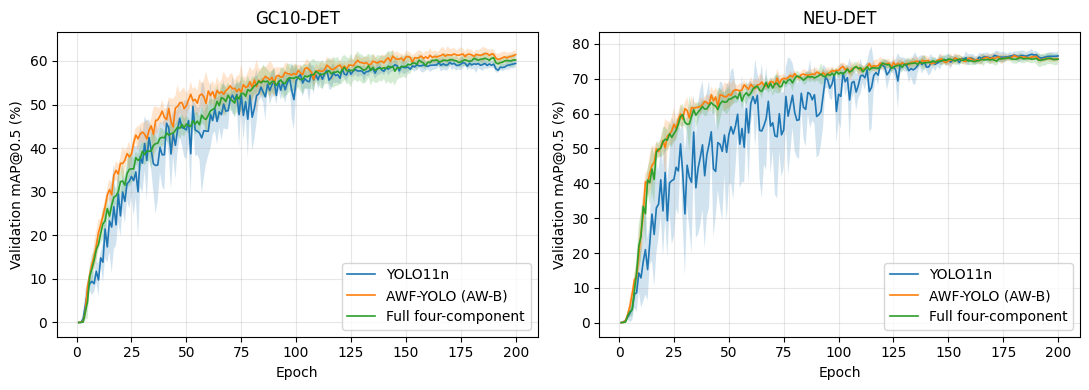

In [ ]:
# 13. (F) Fig. 2: validation mAP@0.5 curves, mean ± SD over five seeds
def curve(n):
    df = pd.read_csv(f'{RUNS}/{resolve(n)}/results.csv'); df.columns = df.columns.str.strip()
    return df.drop_duplicates('epoch', keep='last').sort_values('epoch').set_index('epoch')['metrics/mAP50(B)'] * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (ds, (_, bases)) in zip(axes, fams.items()):
    for base, lab in zip(bases, LABELS):
        c = pd.concat([curve(n) for n in seed_names(base)], axis=1); m_, s_ = c.mean(1), c.std(1)
        ax.plot(m_.index, m_, label=lab, lw=1.2); ax.fill_between(m_.index, m_ - s_, m_ + s_, alpha=.2)
    ax.set(title=f'{ds}-DET', xlabel='Epoch', ylabel='Validation mAP@0.5 (%)'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); [plt.savefig(f'{OUT}/fig10_training_curves.{e}', dpi=300) for e in ('png', 'pdf')]; plt.show()

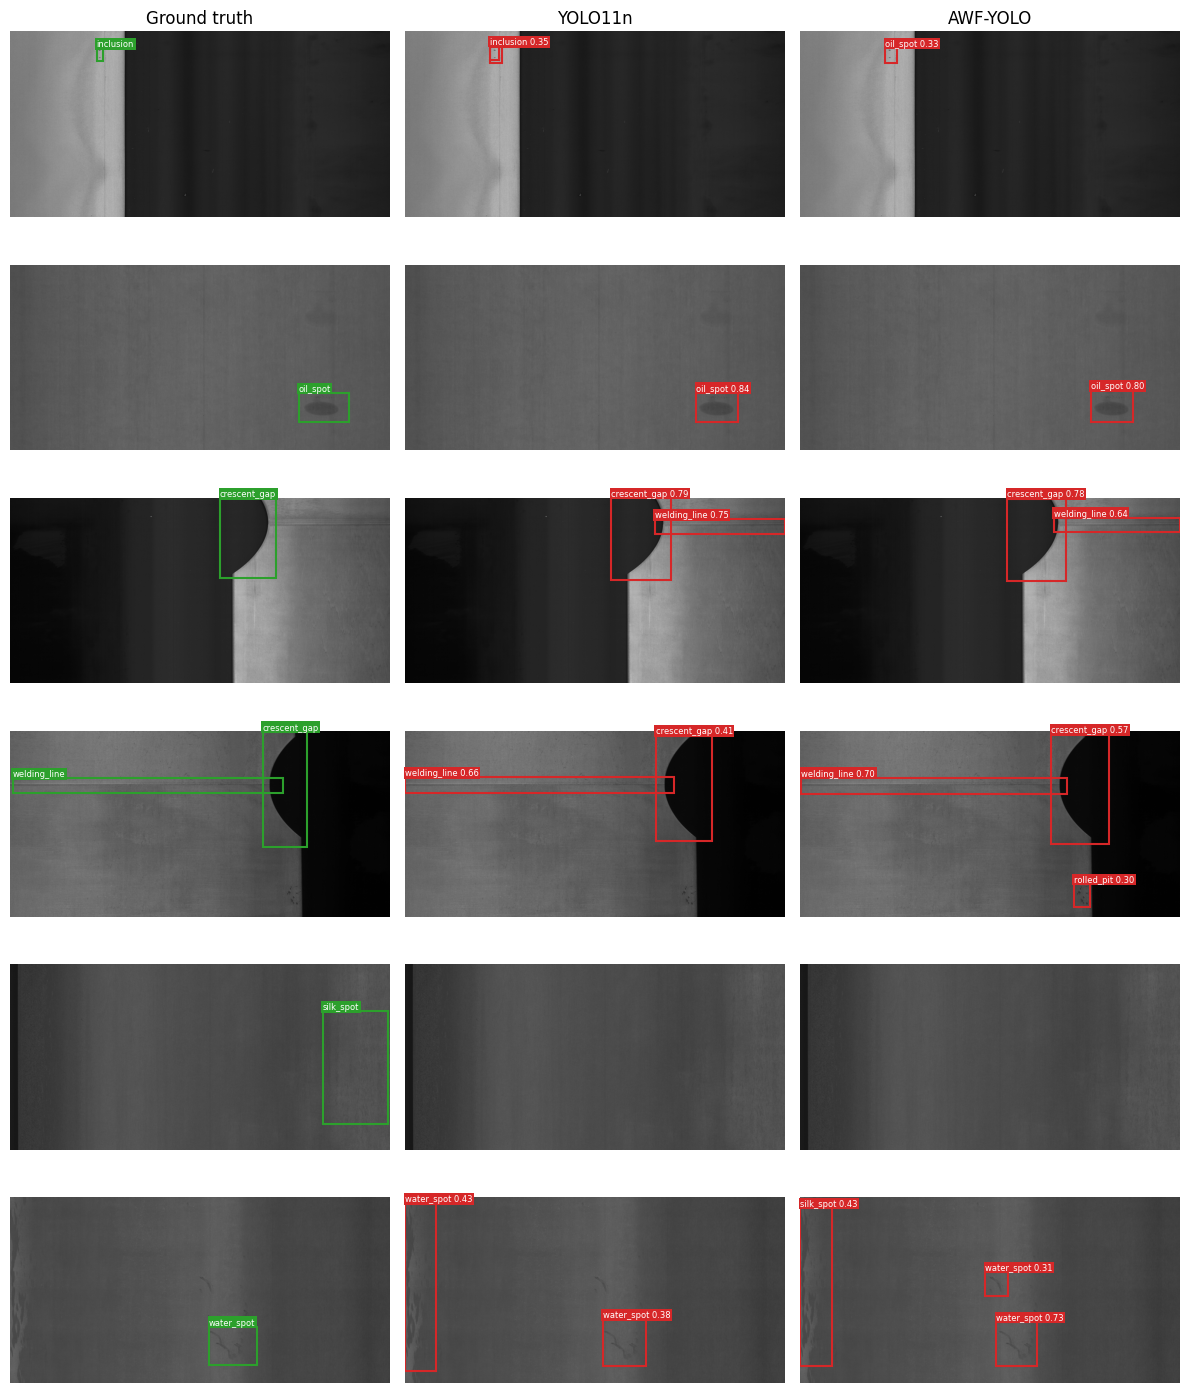

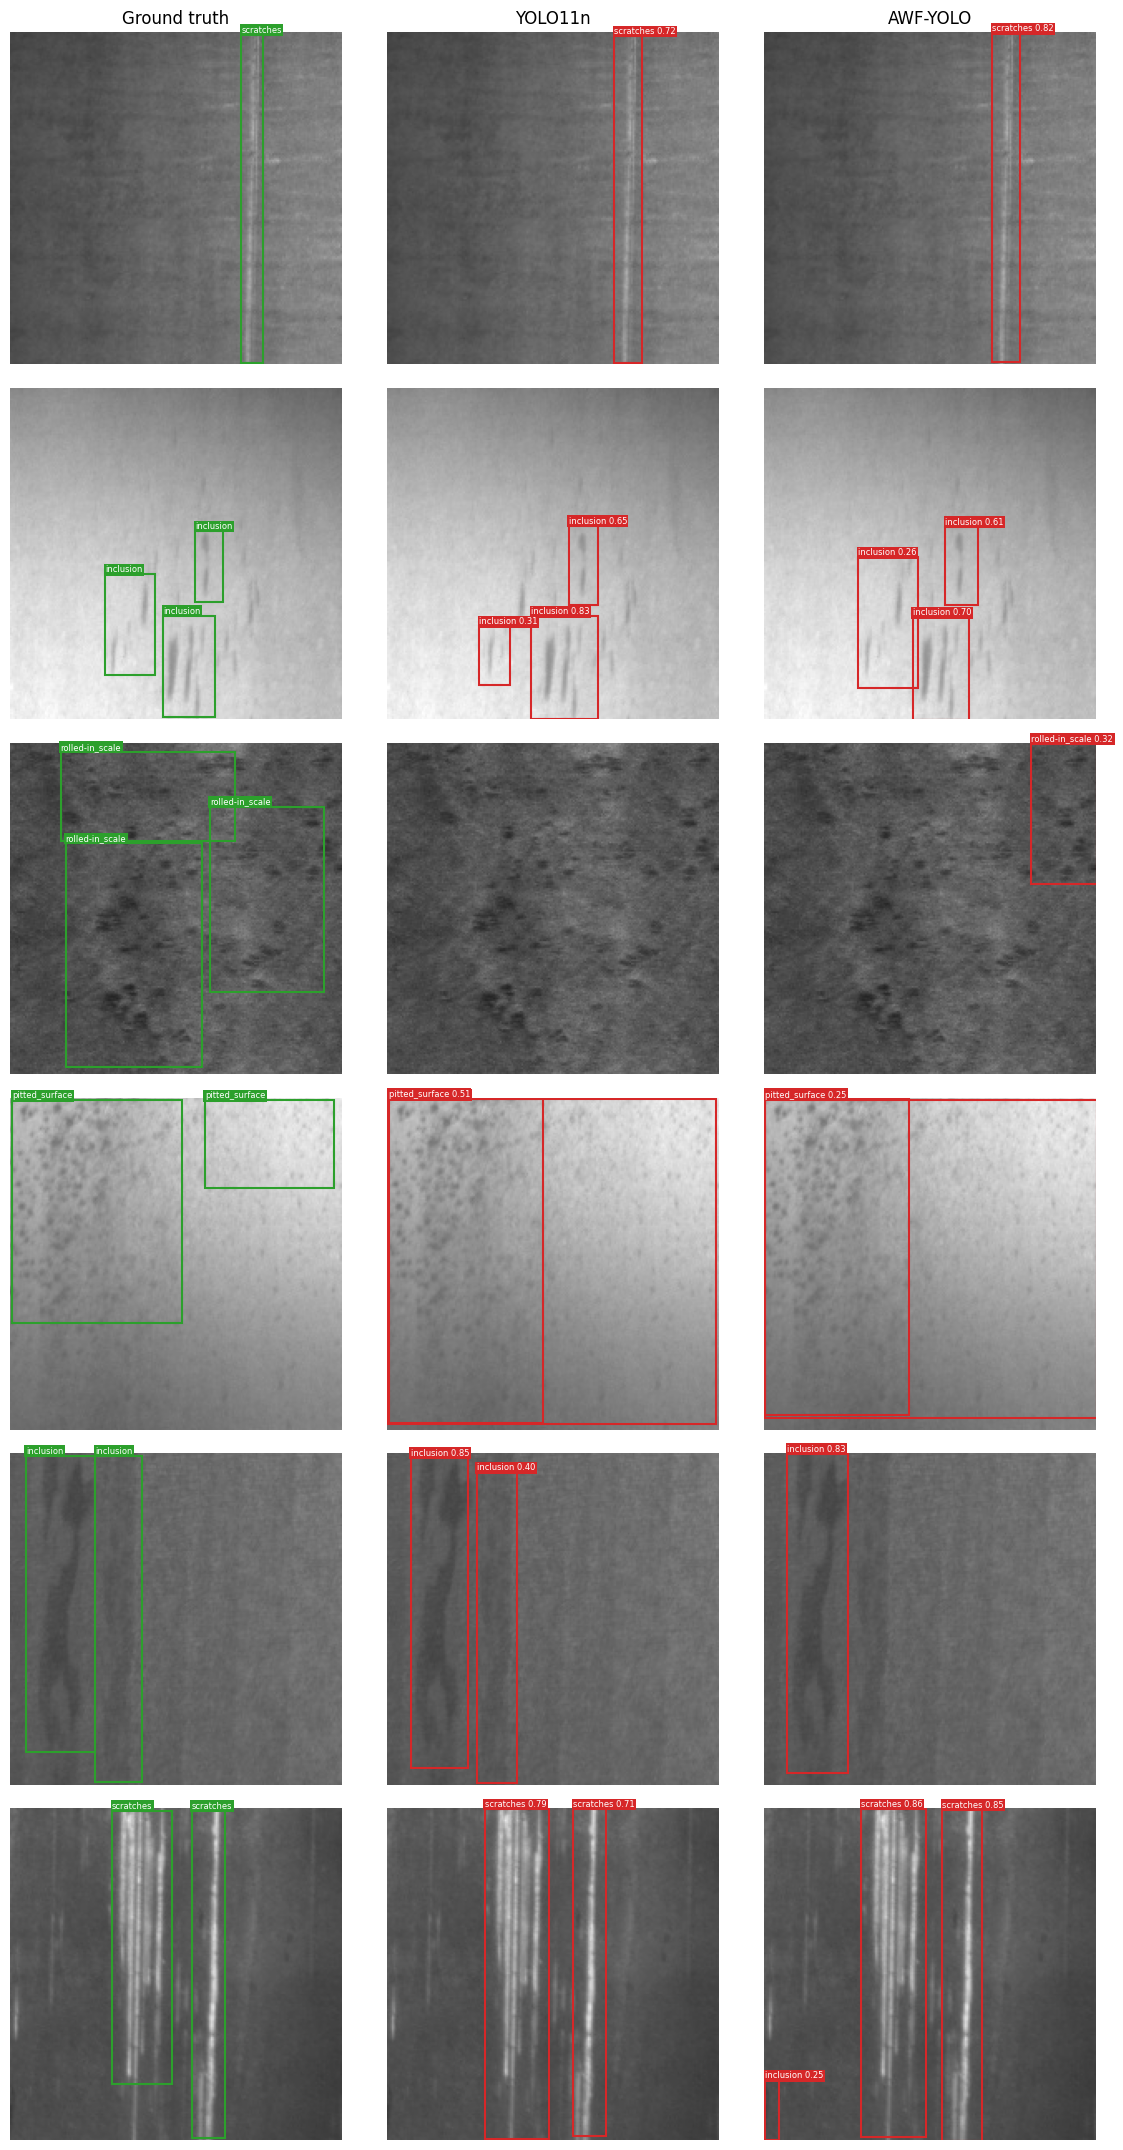

In [ ]:
# 14. (G) Fig. 8 (NEU-DET; the GC10-DET version is not in the paper): random (fixed-seed) qualitative examples, ground truth vs YOLO11n vs AWF-YOLO
def test_images(data):
    d = yaml.safe_load(open(data)); root = d.get('path', os.path.dirname(data)); t = d['test']
    t = t if os.path.isabs(t) else os.path.join(root, t)
    return sorted(glob.glob(f'{t}/*.*')) if os.path.isdir(t) else [l.strip() for l in open(t) if l.strip()]
def gt_boxes(p, w, h):
    lp = os.path.splitext(p.replace('/images/', '/labels/'))[0] + '.txt'; out = []
    for line in (open(lp) if os.path.exists(lp) else []):
        c, xc, yc, bw, bh = map(float, line.split()[:5])
        out.append((int(c), (xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h))
    return out
def draw(ax, img, boxes, names, color):
    ax.imshow(img); ax.axis('off')
    for c, x1, y1, x2, y2, *cf in boxes:
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.5, ec=color))
        ax.text(x1, y1, names[int(c)] + (f' {cf[0]:.2f}' if cf else ''), fontsize=6, color='white', va='bottom', bbox=dict(fc=color, ec='none', pad=1))
def qualitative(ds, data, by, ba, k=6, seed=0):
    imgs = test_images(data); random.Random(seed).shuffle(imgs); imgs = imgs[:k]
    my, ma = load(by), load(ba); names = my.names
    fig, axes = plt.subplots(k, 3, figsize=(12, (2.4 if ds == 'GC10' else 3.6) * k))
    for i, p in enumerate(imgs):
        img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB); h, w = img.shape[:2]
        draw(axes[i, 0], img, gt_boxes(p, w, h), names, 'tab:green')
        for j, m in [(1, my), (2, ma)]:
            b = m.predict(p, conf=0.25, verbose=False)[0].boxes
            draw(axes[i, j], img, [(int(c), *xy, cf) for c, xy, cf in zip(b.cls.tolist(), b.xyxy.tolist(), b.conf.tolist())], names, 'tab:red')
    for j, t in enumerate(['Ground truth', 'YOLO11n', 'AWF-YOLO']): axes[0, j].set_title(t)
    plt.tight_layout(); [plt.savefig(f'{OUT}/fig14_qualitative_{ds}.{e}', dpi=200) for e in ('png', 'pdf')]; plt.show()
qualitative('GC10', GC10, 'gc10_yolo11n', 'gc10_awf-awb'); qualitative('NEU', NEU, 'neu_yolo11n_s0', 'neu_awf-awb_s0')

GC10: energy above 0.25 cycles/px = 2.090% (mean), 1.048% (median), n=345
NEU: energy above 0.25 cycles/px = 0.035% (mean), 0.023% (median), n=180
MannwhitneyuResult(statistic=np.float64(61341.0), pvalue=np.float64(2.776775721960147e-75))


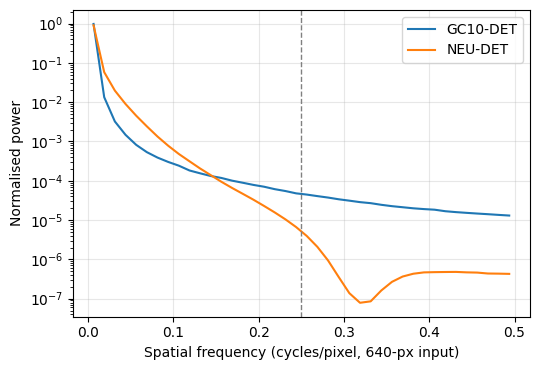

In [ ]:
# 15. (H) Fig. 6: spectral energy above 0.25 cycles/pixel (band a stride-2 layer cannot represent) at the 640-px input
from scipy.stats import mannwhitneyu
def hf_and_spectrum(path, cutoff=0.25, nb=40):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE).astype(np.float32); h, w = g.shape; r = 640 / max(h, w)
    g = cv2.resize(g, (round(w * r), round(h * r)), interpolation=cv2.INTER_LINEAR if r > 1 else cv2.INTER_AREA)
    g -= g.mean(); g *= np.outer(np.hanning(g.shape[0]), np.hanning(g.shape[1])); P = np.abs(np.fft.fft2(g)) ** 2
    fy, fx = np.abs(np.fft.fftfreq(g.shape[0]))[:, None], np.abs(np.fft.fftfreq(g.shape[1]))[None, :]
    frac = P[(fx > cutoff) | (fy > cutoff)].sum() / P.sum()
    rad, bins = np.sqrt(fx ** 2 + fy ** 2), np.linspace(0, 0.5, nb + 1)
    prof = np.array([P[(rad >= bins[i]) & (rad < bins[i + 1])].mean() for i in range(nb)]); return frac, prof / prof.sum()
freq = {}
for ds, (data, _) in fams.items():
    o = [hf_and_spectrum(p) for p in test_images(data)]; freq[ds] = (np.array([x[0] for x in o]), np.mean([x[1] for x in o], 0))
    print(f'{ds}: energy above 0.25 cycles/px = {freq[ds][0].mean()*100:.3f}% (mean), {np.median(freq[ds][0])*100:.3f}% (median), n={len(o)}')
print(mannwhitneyu(freq['GC10'][0], freq['NEU'][0]))
pd.DataFrame({ds: pd.Series(f[0]) for ds, f in freq.items()}).to_csv(f'{OUT}/hf_energy_per_image.csv', index=False)
cen = (np.linspace(0, .5, 41)[:-1] + np.linspace(0, .5, 41)[1:]) / 2
plt.figure(figsize=(5.5, 3.8)); [plt.semilogy(cen, f[1], label=f'{ds}-DET') for ds, f in freq.items()]
plt.axvline(.25, ls='--', c='gray', lw=1); plt.xlabel('Spatial frequency (cycles/pixel, 640-px input)'); plt.ylabel('Normalised power')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); [plt.savefig(f'{OUT}/fig11_spectrum.{e}', dpi=300) for e in ('png', 'pdf')]; plt.show()

In [ ]:
# 16. (J) Table 9 and Fig. 5: controlled-corruption robustness, YOLO11n vs AWF-YOLO (seed 0)
!python scripts/robustness.py --data {GC10} --work /content/corrupt --out {DRIVE}/results/gc10_robust --weights {weights('gc10_yolo11n')} {weights('gc10_awf-awb')}
for f in glob.glob(f'{DRIVE}/results/gc10_robust/*.csv'): print(f); print(pd.read_csv(f).to_string())

Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,584,102 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3916.5±1177.0 MB/s, size: 415.9 KB)
val: Scanning /content/data/gc10/labels/test.cache... 345 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 345/345 57.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 3.1it/s 7.1s
                   all        345        537      0.693      0.643      0.648      0.316
Speed: 1.1ms preprocess, 4.1ms inference, 0.0ms loss, 2.7ms postprocess per image
{'model': 'gc10_yolo11n', 'condition': 'clean', 'mAP50': 64.8, 'retention_pct': 100.0}
Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,584,102 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 133.6±80.2 M

{'false_negative': 155, 'false_positive': 117, 'wrong_class': 22, 'merged': 13} -> see /content/drive/MyDrive/AWF-YOLO-v2/results/paper/failures
figure examples: {'false_negative': 'img_06_4406645900_00291.jpg', 'false_positive': 'img_08_424799400_01080.jpg', 'wrong_class': 'img_05_4406645900_00121.jpg', 'merged': 'img_03_425505400_01033.jpg'}


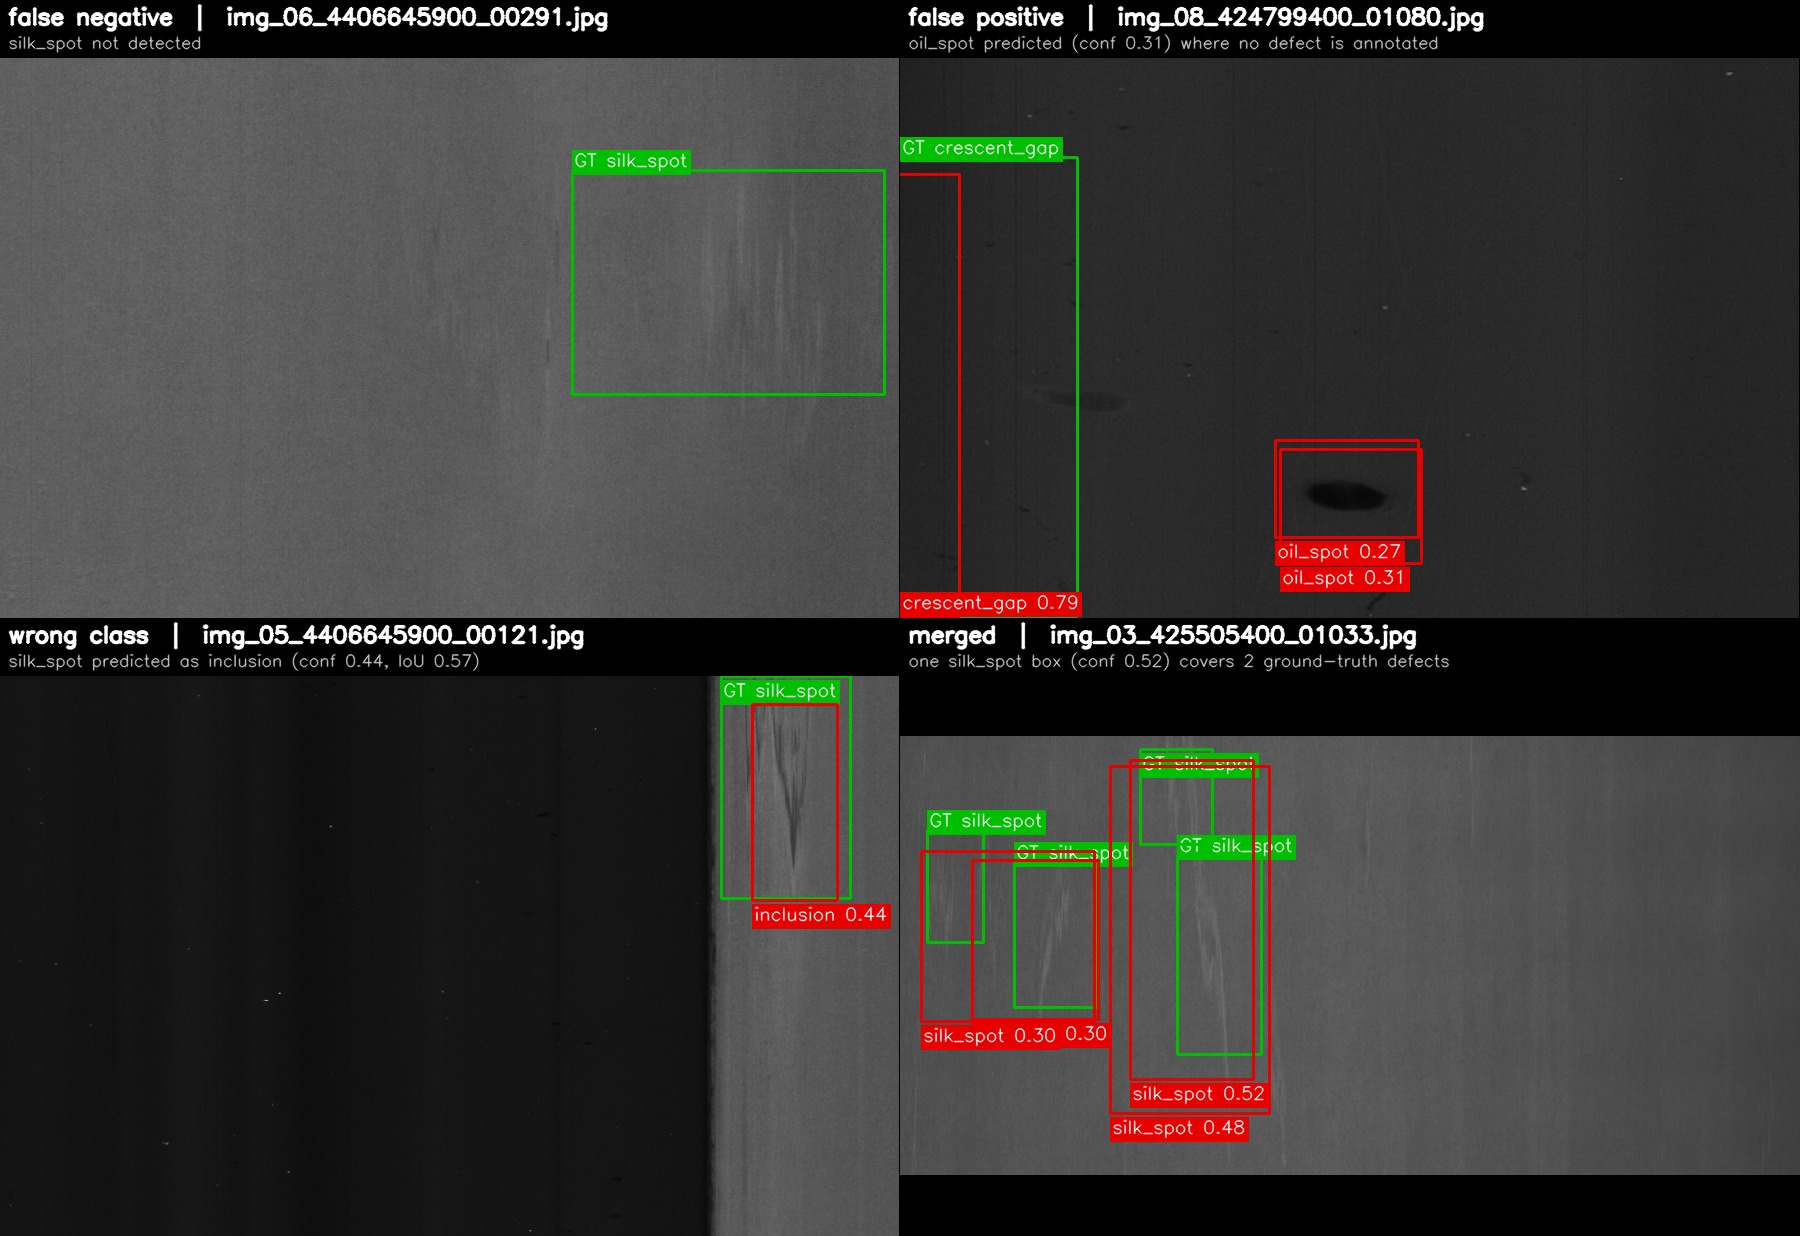

In [ ]:
# 17. (K) Fig. 9: annotated failure cases of AWF-YOLO (seed 0)
!python scripts/failure_cases.py --weights {weights('gc10_awf-awb')} --data {GC10} --out {OUT}/failures
from IPython.display import Image, display; display(Image(f'{OUT}/failures/figure_failure_cases.jpg', width=1000))

In [ ]:
# 18. Package results (CSV, figures, environment) into results/awf_paper_results.zip
import platform
json.dump(dict(python=platform.python_version(), torch=torch.__version__, ultralytics=ultralytics.__version__,
               cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0)), open(f'{OUT}/environment.json', 'w'), indent=2)
for f in ['gc10_final', 'neu_final', 'gc10_extra', 'gc10_robust']:
    for c in glob.glob(f'{DRIVE}/results/{f}/*.csv'): os.makedirs(f'{OUT}/{f}', exist_ok=True); shutil.copy(c, f'{OUT}/{f}/')
print('saved', shutil.make_archive(f'{DRIVE}/results/awf_paper_results', 'zip', OUT))

saved /content/drive/MyDrive/AWF-YOLO-v2/results/awf_paper_results.zip


## Input-size experiment on NEU-DET (Table 10, Fig. 7)

Tests whether the dataset dependence follows from spectral content: YOLO11n and AWF-YOLO are retrained on NEU-DET at
224 px (1.12× upsampling of the native 200 px) and 320 px (1.60×); the 640-px runs from cell 5 are reused.

| Step | Cell | What it does |
|---|---|---|
| 1 | N0 | Session setup and statistics helpers (run after cells 1–4) |
| 2 | N1 | Enables a non-default input size and checks it with a ~2-minute smoke test |
| 3 | N2 | Estimates run times from the finished runs |
| 4 | N3 | Trains NEU-DET at 224 and 320 px, 5 seeds, YOLO11n and AWF-YOLO |
| 5 | N4 | Test evaluation at the size each model was trained at, with a check against cell 7 |
| 6 | N5 | Exact permutation tests, Holm adjustment, bootstrap intervals and Fig. 7 |
| 7 | N6 | Spectral energy above 0.25 cycles/px for NEU-DET at each size and GC10-DET at 640 px |
| 8 | S1–S5 | Severstal subset (Tables 11 and 12) |
| 9 | N8 | Packages the results |

Caveat (Section 5.9.3): a smaller input also makes defects smaller in pixels, so frequency content and object scale are confounded.


In [ ]:
# N0. Session setup + helpers for the additions (run after cells 1-4; safe to re-run)
import sys, os, re, json, glob, itertools, math, shutil, subprocess
import numpy as np, pandas as pd, cv2, yaml
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
sys.path.insert(0, '/content/awf_yolo_v2'); import awf        # registers AWB etc. so best.pt files can be loaded
from ultralytics import YOLO
NEW = f'{DRIVE}/results/additions'; os.makedirs(NEW, exist_ok=True)
def weights(name): return f'{RUNS}/{resolve(name)}/weights/best.pt'
def load(name): return YOLO(weights(name))
def family(df): df['family'] = df['model'].str.replace(r'_s\d.*$', '', regex=True); return df

def holm(p):
    o, m, adj, run_ = np.argsort(p), len(p), np.empty(len(p)), 0
    for i, j in enumerate(o): run_ = max(run_, (m - i) * p[j]); adj[j] = min(run_, 1)
    return adj
def perm_p(a, b):                                  # exact two-sided permutation test on the difference of means
    pool, n, obs, hit, tot = np.r_[a, b], len(a), abs(np.mean(a) - np.mean(b)), 0, 0
    for c in itertools.combinations(range(len(pool)), n):
        m = np.zeros(len(pool), bool); m[list(c)] = True
        hit += abs(pool[m].mean() - pool[~m].mean()) >= obs - 1e-12; tot += 1
    return hit / tot
def compare(df, fa, fb, metrics=('mAP50', 'mAP50_95', 'precision', 'recall', 'F1'), seed=0):
    rng, rows = np.random.default_rng(seed), []
    for k in metrics:
        a, b = (df.loc[df.family == f, k].astype(float).to_numpy() for f in (fa, fb))
        assert len(a) > 1 and len(b) > 1, f'need >=2 seeds per group for {fa} / {fb}'
        d = a.mean() - b.mean(); sp = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
        boot = rng.choice(a, (10000, len(a))).mean(1) - rng.choice(b, (10000, len(b))).mean(1)
        rows.append(dict(comparison=f'{fa} vs {fb}', metric=k, n_A=len(a), n_B=len(b), mean_A=a.mean(), mean_B=b.mean(), diff=d,
                         ci95_lo=np.percentile(boot, 2.5), ci95_hi=np.percentile(boot, 97.5), cohen_d=d / sp if sp > 0 else np.nan,
                         p_perm=perm_p(a, b), p_holm=np.nan, min_p=2 / math.comb(len(a) + len(b), len(a))))
    r = pd.DataFrame(rows); pri = r.metric.isin(['mAP50', 'mAP50_95']).to_numpy()
    if pri.any(): r.loc[pri, 'p_holm'] = holm(r.loc[pri, 'p_perm'].to_numpy())   # Holm over the two primary metrics only
    return r

def test_imgs(data):
    d = yaml.safe_load(open(data)); root = d.get('path', os.path.dirname(data)); t = d['test']
    t = t if os.path.isabs(t) else os.path.join(root, t)
    return sorted(glob.glob(f'{t}/*.*')) if os.path.isdir(t) else [l.strip() for l in open(t) if l.strip()]
def hf_at(path, size, cutoff=0.25):               # same computation as cell 15 (Hann window; |fx| or |fy| > cutoff), at a chosen input size
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE).astype(np.float32); h, w = g.shape; r = size / max(h, w)
    g = cv2.resize(g, (round(w * r), round(h * r)), interpolation=cv2.INTER_LINEAR if r > 1 else cv2.INTER_AREA)
    g -= g.mean(); g *= np.outer(np.hanning(g.shape[0]), np.hanning(g.shape[1])); P = np.abs(np.fft.fft2(g)) ** 2
    fy, fx = np.abs(np.fft.fftfreq(g.shape[0]))[:, None], np.abs(np.fft.fftfreq(g.shape[1]))[None, :]
    return float(P[(fx > cutoff) | (fy > cutoff)].sum() / P.sum())
print('helpers ready; additions folder:', NEW)

helpers ready; additions folder: /content/drive/MyDrive/AWF-YOLO-v2/results/additions


In [ ]:
# N1. Allow a non-default input size, then PROVE it with a smoke test (once per session; ~2 min)
print(subprocess.run('grep -n "imgsz" scripts/*.py awf/*.py || true', shell=True, capture_output=True, text=True).stdout or '(no "imgsz" in scripts/ or awf/)')
ENV_EXPR = "imgsz=int(__import__('os').environ.get('AWF_IMGSZ', '640'))"
IMGSZ_MODE = None
if '--imgsz' in open('scripts/train.py').read():
    IMGSZ_MODE = 'arg'                                                      # train.py already exposes --imgsz
else:
    for p in ('awf/trainer.py', 'scripts/train.py'):
        s = open(p).read()
        if 'AWF_IMGSZ' in s: IMGSZ_MODE = 'env'; break                      # patched earlier in this or a previous session
        if re.search(r'imgsz\s*=\s*640', s):
            open(p, 'w').write(re.sub(r'imgsz\s*=\s*640', ENV_EXPR, s, count=1)); IMGSZ_MODE = 'env'; print('patched', p); break
    else:
        s = open('awf/trainer.py').read()
        if 'imgsz' not in s and 'plots=True, exist_ok=True,' in s:          # imgsz was never set: add it to the train kwargs
            open('awf/trainer.py', 'w').write(s.replace('plots=True, exist_ok=True,', f'plots=True, exist_ok=True, {ENV_EXPR},', 1)); IMGSZ_MODE = 'env'; print('inserted imgsz into awf/trainer.py')
if IMGSZ_MODE is None:
    raise RuntimeError('Could not find where the training size is set. See the grep output above.')
IMGSZ_ARG = lambda sz: f'--imgsz {sz}' if IMGSZ_MODE == 'arg' else ''

def smoke(sz=224):
    os.environ['AWF_IMGSZ'] = str(sz); shutil.rmtree('/content/smoke', ignore_errors=True)
    r = subprocess.run(f'timeout -k 10 150 python scripts/train.py --model awf-awb --data {NEU} --name smoke --project /content/smoke {IMGSZ_ARG(sz)}',
                       shell=True, capture_output=True, text=True)
    f = glob.glob('/content/smoke/smoke*/args.yaml')
    assert f, 'smoke run wrote no args.yaml; last output:\n' + (r.stdout + r.stderr)[-1500:]
    got = yaml.safe_load(open(f[0]))['imgsz']
    assert int(got) == sz, f'training ran at imgsz={got}, expected {sz}'
    shutil.rmtree('/content/smoke', ignore_errors=True)
    print(f'OK: training picks up imgsz={got} (mode: {IMGSZ_MODE})')
smoke(224)

scripts/00_selftest.py:30:def gflops(model, imgsz=640):
scripts/00_selftest.py:34:        macs, _ = thop.profile(m, inputs=(torch.zeros(1, 3, imgsz, imgsz),), verbose=False)
scripts/edge_benchmark.py:8:e = sub.add_parser("export"); e.add_argument("--weights", required=True); e.add_argument("--imgsz", type=int, default=640)
scripts/edge_benchmark.py:10:r.add_argument("--n", type=int, default=300); r.add_argument("--imgsz", type=int, default=640)
scripts/edge_benchmark.py:16:    p = YOLO(a.weights).export(format="onnx", imgsz=a.imgsz, opset=12, simplify=True)
scripts/edge_benchmark.py:25:    prep = lambda f: np.ascontiguousarray(cv2.resize(cv2.imread(f), (a.imgsz, a.imgsz))[:, :, ::-1].transpose(2, 0, 1), dtype=np.float32)[None] / 255.0
scripts/evaluate.py:17:def gflops(model, imgsz=640):
scripts/evaluate.py:21:        macs, _ = thop.profile(m, inputs=(torch.zeros(1, 3, imgsz, imgsz),), verbose=False)
scripts/evaluate.py:29:ap.add_argument("--out", required=True); ap.add_argument("--imgs

In [ ]:
# N2. Measured wall-clock of your finished runs -> planning estimates (no GPU work)
def run_hours(name):
    f = f'{RUNS}/{resolve(name)}/results.csv'
    if not os.path.exists(f): return float('nan')
    df = pd.read_csv(f); df.columns = df.columns.str.strip()
    return float(df['time'].iloc[-1]) / 3600 if 'time' in df.columns else float('nan')
t_neu = np.nanmean([run_hours('neu_yolo11n_s0'), run_hours('neu_awf-awb_s0')])
t_gc = np.nanmean([run_hours('gc10_yolo11n'), run_hours('gc10_awf-awb')])
print(f'measured: NEU-DET @640 {t_neu:.2f} h/run | GC10-DET @640 {t_gc:.2f} h/run (1,610 train images)')
for sz in (224, 320, 416):
    lo, hi = t_neu * (sz / 640) ** 2, t_neu * (sz / 640)     # cost ~ pixels at best; small inputs are partly data-loader bound, so the real saving is smaller
    print(f'  NEU-DET @{sz}: {lo:.2f}-{hi:.2f} h/run -> 10 runs = {10*lo:.1f}-{10*hi:.1f} h')
per_sev = t_gc * 2800 / 1610                                  # 4,000-image subset, 70% train
print(f'Severstal @640 (~2,800 train images): ~{per_sev:.1f} h/run -> 6 runs (3 seeds) = {6*per_sev:.0f} h, 10 runs (5 seeds) = {10*per_sev:.0f} h')

measured: NEU-DET @640 0.84 h/run | GC10-DET @640 2.20 h/run (1,610 train images)
  NEU-DET @224: 0.10-0.30 h/run -> 10 runs = 1.0-3.0 h
  NEU-DET @320: 0.21-0.42 h/run -> 10 runs = 2.1-4.2 h
  NEU-DET @416: 0.36-0.55 h/run -> 10 runs = 3.6-5.5 h
Severstal @640 (~2,800 train images): ~3.8 h/run -> 6 runs (3 seeds) = 23 h, 10 runs (5 seeds) = 38 h


In [ ]:
# N3. NEU-DET at reduced input sizes (the 640-px runs from cell 5 are reused). Re-run after any disconnect.
NEU_SIZES = [224, 320]           # 224 is the native 200 px rounded up to a multiple of 32 (416 px was started but not completed)
for sz in NEU_SIZES:
    os.environ['AWF_IMGSZ'] = str(sz)
    for s in range(5):
        for model, base in [('yolo11n.yaml', 'yolo11n'), ('awf-awb', 'awf-awb')]:
            run(model, NEU, f'neu{sz}_{base}_s{s}', f'--seed {s} {IMGSZ_ARG(sz)}')

In [ ]:
# N4. Test evaluation at the SAME size each model was trained at. 640-px runs are re-evaluated with the same code for a like-for-like trend.
SIZES = [224, 320, 640]
def pre(sz): return 'neu_' if sz == 640 else f'neu{sz}_'
def eval_run(name, data, sz):
    n = resolve(name); assert progress(f'{RUNS}/{n}') == 10**6, f'{n} is not finished'
    got = yaml.safe_load(open(f'{RUNS}/{n}/args.yaml'))['imgsz']; assert int(got) == sz, f'{n} was trained at imgsz={got}, expected {sz}'
    m = load(name); r = m.val(data=data, split='test', imgsz=sz, conf=0.001, iou=0.7, batch=16, plots=False, verbose=False)
    P, R = float(r.box.mp), float(r.box.mr)
    return dict(model=n, imgsz=sz, mAP50=100 * float(r.box.map50), mAP50_95=100 * float(r.box.map), precision=100 * P, recall=100 * R,
                F1=2 * P * R / (P + R + 1e-12), params_M=sum(p.numel() for p in m.model.parameters()) / 1e6)
rows = [eval_run(f'{pre(sz)}{base}_s{s}', NEU, sz) for sz in SIZES for s in range(5) for base in ('yolo11n', 'awf-awb')]
neu_sz = pd.DataFrame(rows); neu_sz.to_csv(f'{NEW}/neu_native_summary.csv', index=False)
old = pd.read_csv(f'{DRIVE}/results/neu_final/summary.csv').set_index('model')            # consistency check against cell 7
chk = neu_sz[neu_sz.imgsz == 640].set_index('model').join(old[['mAP50']], rsuffix='_cell7')
print('max |mAP50 difference| vs cell 7 on the 640 runs:', round(float((chk.mAP50 - chk.mAP50_cell7).abs().max()), 3), '(expect < 0.1)')
print(neu_sz.assign(family=lambda d: d.model.str.replace(r'_s\d.*$', '', regex=True)).groupby('family')[['mAP50', 'mAP50_95', 'precision', 'recall']].agg(['mean', 'std']).round(2).to_string())

In [ ]:
# N5. Seed-level statistics by input size (AWF-YOLO = AW-B vs YOLO11n) + trend figure
df = family(pd.read_csv(f'{NEW}/neu_native_summary.csv'))
T = pd.concat([compare(df[df.imgsz == sz], f'{pre(sz)}awf-awb', f'{pre(sz)}yolo11n').assign(imgsz=sz) for sz in SIZES])
T.to_csv(f'{NEW}/neu_native_stats.csv', index=False)
pd.set_option('display.width', 220)
print(T[['imgsz', 'metric', 'mean_A', 'mean_B', 'diff', 'ci95_lo', 'ci95_hi', 'cohen_d', 'p_perm', 'p_holm']].round(3).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.9), sharey=True)                # Fig. 7, logarithmic size axis
for ax, k, lab in zip(axes, ['mAP50', 'mAP50_95'], ['mAP@0.5', 'mAP@0.5:0.95']):
    r = T[T.metric == k].sort_values('imgsz')
    ax.errorbar(r.imgsz, r['diff'], yerr=[r['diff'] - r.ci95_lo, r.ci95_hi - r['diff']], fmt='o-', capsize=3)
    ax.axhline(0, color='0.4', lw=.8, ls='--'); ax.set_xscale('log'); ax.minorticks_off()
    ax.set_xticks(r.imgsz); ax.set_xticklabels([f'{s}\n({s/200:.2f}×)' for s in r.imgsz])
    ax.set(title=f'Δ {lab}', xlabel='Input size, px (upsampling)'); ax.grid(alpha=.3)
axes[0].set_ylabel('AWF-YOLO − YOLO11n (points)'); plt.tight_layout()
[plt.savefig(f'{NEW}/Fig7_input_size_trend.{e}', dpi=600) for e in ('png', 'pdf')]; plt.show()


{'dataset': 'GC10', 'imgsz': 640, 'upsample': nan, 'n': 345, 'mean_pct': np.float64(2.0899204778960785), 'median_pct': np.float64(1.0484364815056324)}
{'dataset': 'NEU', 'imgsz': 224, 'upsample': 1.12, 'n': 180, 'mean_pct': np.float64(2.0943004766660227), 'median_pct': np.float64(1.0850407183170319)}
{'dataset': 'NEU', 'imgsz': 320, 'upsample': 1.6, 'n': 180, 'mean_pct': np.float64(0.7586536764655547), 'median_pct': np.float64(0.35054036416113377)}
{'dataset': 'NEU', 'imgsz': 640, 'upsample': 3.2, 'n': 180, 'mean_pct': np.float64(0.03543456013782512), 'median_pct': np.float64(0.023126802989281714)}
NEU@224 vs GC10@640 Mann-Whitney p = 2.83e-02
NEU@320 vs GC10@640 Mann-Whitney p = 4.02e-08
NEU@640 vs GC10@640 Mann-Whitney p = 2.78e-75


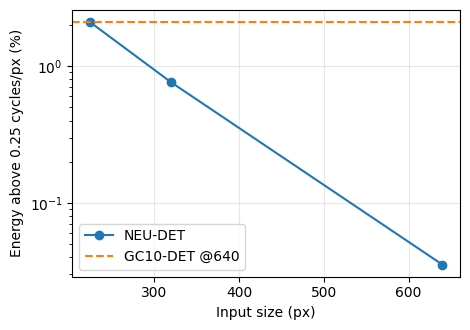

In [ ]:
# N6. Spectral energy above 0.25 cycles/px: NEU-DET at each size vs GC10-DET at 640 (the 640 rows should reproduce cell 15: GC10 2.090%, NEU 0.035%)
rows, store = [], {}
for ds, data, szs in [('GC10', GC10, [640]), ('NEU', NEU, SIZES)]:
    imgs = test_imgs(data)
    for sz in szs:
        v = np.array([hf_at(p, sz) for p in imgs]); store[(ds, sz)] = v
        rows.append(dict(dataset=ds, imgsz=sz, upsample=round(sz / 200, 2) if ds == 'NEU' else np.nan, n=len(v), mean_pct=100 * v.mean(), median_pct=100 * np.median(v)))
        print(rows[-1])
H = pd.DataFrame(rows); H.to_csv(f'{NEW}/hf_energy_by_size.csv', index=False)
for sz in SIZES: print(f'NEU@{sz} vs GC10@640 Mann-Whitney p = {mannwhitneyu(store[("NEU", sz)], store[("GC10", 640)]).pvalue:.2e}')
plt.figure(figsize=(4.8, 3.4)); h = H[H.dataset == 'NEU'].sort_values('imgsz')
plt.semilogy(h.imgsz, h.mean_pct, 'o-', label='NEU-DET'); plt.axhline(H[H.dataset == 'GC10'].mean_pct.iloc[0], color='C1', ls='--', label='GC10-DET @640')
plt.xlabel('Input size (px)'); plt.ylabel('Energy above 0.25 cycles/px (%)'); plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
[plt.savefig(f'{NEW}/fig_hf_energy_by_size.{e}', dpi=300) for e in ('png', 'pdf')]; plt.show()

In [ ]:
# N5b. Sensitivity check (Section 5.9.2): 224 px without seed 2, the run that was retrained from scratch
df = family(pd.read_csv(f'{NEW}/neu_native_summary.csv'))
sub = df[(df.imgsz == 224) & (~df.model.str.endswith('_s2'))]
print(compare(sub, 'neu224_awf-awb', 'neu224_yolo11n')[['metric','n_A','n_B','diff','ci95_lo','ci95_hi','p_perm','p_holm','min_p']].round(3).to_string(index=False))

   metric  n_A  n_B   diff  ci95_lo  ci95_hi  p_perm  p_holm  min_p
    mAP50    4    4 -2.188   -3.631   -0.731   0.057   0.057  0.029
 mAP50_95    4    4 -1.491   -2.658   -0.501   0.029   0.057  0.029
precision    4    4 -0.622   -9.348    8.243   0.943     NaN  0.029
   recall    4    4  0.287   -4.579    4.487   0.914     NaN  0.029
       F1    4    4 -0.005   -0.033    0.016   0.914     NaN  0.029


## Severstal subset (Tables 11 and 12)

Severstal strips are 1,600 px wide, so at a 640-px input they are **downscaled 2.5×**, like GC10-DET. The frequency explanation therefore predicts AW-B ≥ YOLO11n here.

**Seeds.** An exact permutation test with 3 vs 3 seeds can never give p below 0.1 (2/20), so 3 seeds cannot show significance. S2 defaults to 5 seeds and interleaves models seed by seed, so seeds 0–2 can be reported descriptively if time runs out, and seeds 3–4 added later. Each run takes about 3.8 h on a T4.

**Credentials.** S1 reads it from Drive, or from Colab Secrets (`KAGGLE_USERNAME`, `KAGGLE_KEY`), or asks you to upload it once. You must also accept the competition rules at https://www.kaggle.com/c/severstal-steel-defect-detection/rules.

**Subset.** 4,000 defective images (seed-42 shuffle), split 70/15/15; one box per 8-connected mask component of at least 30 pixels (`scripts/prepare_severstal.py`).

In [ ]:
# S1. Kaggle credentials + Severstal data (4,000-image subset, seed-42 70/15/15), cached to Drive
SEV = f'{DATA}/severstal/severstal.yaml'; TAR = f'{DRIVE}/data/severstal.tar'
def ensure_kaggle_json():
    kj = f'{DRIVE}/kaggle.json'
    if os.path.exists(kj): return kj
    try:                                                    # option A: Colab Secrets named KAGGLE_USERNAME and KAGGLE_KEY
        from google.colab import userdata
        json.dump({'username': userdata.get('KAGGLE_USERNAME'), 'key': userdata.get('KAGGLE_KEY')}, open(kj, 'w')); return kj
    except Exception as e: print('no usable Colab secrets:', type(e).__name__)
    from google.colab import files                          # option B: upload once; it is then kept on Drive
    print('Upload kaggle.json (kaggle.com > Settings > API > Create New Token)')
    up = files.upload(); assert up, 'no file uploaded'
    open(kj, 'wb').write(next(iter(up.values()))); return kj
if not os.path.exists(SEV):
    if os.path.exists(TAR):
        subprocess.run(f'mkdir -p {DATA} && tar -xf "{TAR}" -C {DATA}', shell=True, check=True)
        subprocess.run(f'sed -i "s#^path:.*#path: {DATA}/severstal#" {SEV}', shell=True, check=True)
    else:
        kj = ensure_kaggle_json()
        subprocess.run(f'mkdir -p ~/.kaggle && cp "{kj}" ~/.kaggle/kaggle.json && chmod 600 ~/.kaggle/kaggle.json', shell=True, check=True)
        r = subprocess.run('kaggle competitions download -c severstal-steel-defect-detection -p /content/severstal && cd /content/severstal && unzip -q -o severstal-steel-defect-detection.zip',
                           shell=True, capture_output=True, text=True)
        assert r.returncode == 0, ('Download failed. On a 403, open https://www.kaggle.com/c/severstal-steel-defect-detection/rules and accept the rules.\n' + (r.stdout + r.stderr)[-800:])
        subprocess.run(f'python scripts/prepare_severstal.py --root /content/severstal --out {DATA}/severstal --max-images 4000', shell=True, check=True)
        subprocess.run(f'mkdir -p "{DRIVE}/data" && tar -cf "{TAR}" -C {DATA} severstal', shell=True, check=True)
print(open(SEV).read())
for sp in ('train', 'val', 'test'): print(sp, len(os.listdir(f'{DATA}/severstal/images/{sp}')), 'images')

path: /content/data/severstal
train: images/train
val: images/val
test: images/test
names:
  0: defect_1
  1: defect_2
  2: defect_3
  3: defect_4

train 2800 images
val 600 images
test 600 images


In [ ]:
# S1b. Severstal box counts per split and class (Section 5.10)
import glob, collections
for sp in ('train', 'val', 'test'):
    files = glob.glob(f'{DATA}/severstal/labels/{sp}/*.txt')
    c, empty = collections.Counter(), 0
    for f in files:
        L = [l.split()[0] for l in open(f) if l.strip()]
        empty += (len(L) == 0); c.update(L)
    print(sp, len(files), 'label files |', empty, 'empty |', dict(sorted(c.items())))

train 2800 label files | 0 empty | {'0': 1346, '1': 134, '2': 6090, '3': 780}
val 600 label files | 0 empty | {'0': 369, '1': 22, '2': 1373, '3': 162}
test 600 label files | 0 empty | {'0': 232, '1': 30, '2': 1329, '3': 175}


In [ ]:
# S2. Severstal training queue, YOLO11n vs AWF-YOLO (AW-B). Re-run after any disconnect; finished runs are skipped.
SEV_SEEDS = [0, 1, 2, 3, 4]      # [0, 1, 2] for a first pass (descriptive only: 3 vs 3 seeds cannot give p < 0.1)
os.environ['AWF_IMGSZ'] = '640'
for s in SEV_SEEDS:
    run('yolo11n.yaml', SEV, f'sev_yolo11n_s{s}', f'--seed {s}')          # run(model, data, name, extra): the old cell passed these in the wrong order
    run('awf-awb', SEV, f'sev_awf-awb_s{s}', f'--seed {s}')

[skip] sev_yolo11n_s0 already finished
[skip] sev_awf-awb_s0 already finished
[skip] sev_yolo11n_s1 already finished
[skip] sev_awf-awb_s1 already finished
[skip] sev_yolo11n_s2 already finished
[skip] sev_awf-awb_s2 already finished
[skip] sev_yolo11n_s3 already finished
[skip] sev_awf-awb_s3 already finished
[skip] sev_yolo11n_s4 already finished
[skip] sev_awf-awb_s4 already finished


In [ ]:
# S3. Severstal test evaluation (same evaluate.py as GC10/NEU) + seed-level statistics
names = [resolve(f'{b}_s{s}') for s in SEV_SEEDS for b in ['sev_yolo11n', 'sev_awf-awb']]
assert all(progress(f'{RUNS}/{n}') == 10**6 for n in names), 'Severstal runs are not finished; re-run S2'
w = ' '.join(f'{RUNS}/{n}/weights/best.pt' for n in names)
!python scripts/evaluate.py --data {SEV} --out {DRIVE}/results/sev_final --weights {w}
sev = family(pd.read_csv(f'{DRIVE}/results/sev_final/summary.csv'))
print(sev.groupby('family')[['mAP50', 'mAP50_95', 'precision', 'recall', 'F1', 'params_M', 'GFLOPs']].agg(['mean', 'std']).round(2).T.to_string())
S = compare(sev, 'sev_awf-awb', 'sev_yolo11n'); S.to_csv(f'{NEW}/sev_stats.csv', index=False)
print(S[['metric', 'n_A', 'n_B', 'mean_A', 'mean_B', 'diff', 'ci95_lo', 'ci95_hi', 'cohen_d', 'p_perm', 'p_holm', 'min_p']].round(3).to_string(index=False))

Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,932 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2595.5±870.6 MB/s, size: 122.3 KB)
val: Scanning /content/data/severstal/labels/test... 600 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 600/600 1.6Kit/s 0.4s
val: New cache created: /content/data/severstal/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 6.9it/s 5.5s
                   all        600       1766      0.581      0.465       0.47      0.219
Speed: 0.3ms preprocess, 1.9ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /content/drive/.shortcut-targets-by-id/1IPx7TPbDZitkk4bahYkv3USXh7P6W1no/AWF-YOLO-v2/results/sev_final/sev_yolo11n_s0
Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layer

In [ ]:
# S4. Spectral energy of the Severstal test images at the 640-px input (compare with GC10-DET and NEU-DET from N6)
v = np.array([hf_at(p, 640) for p in test_imgs(SEV)])
print(f'Severstal @640: energy above 0.25 cycles/px = {100*v.mean():.3f}% (mean), {100*np.median(v):.3f}% (median), n={len(v)}')
if 'store' in globals():
    print(f'vs GC10@640 Mann-Whitney p = {mannwhitneyu(v, store[("GC10", 640)]).pvalue:.2e}; vs NEU@640 p = {mannwhitneyu(v, store[("NEU", 640)]).pvalue:.2e}')
pd.DataFrame([dict(dataset='Severstal', imgsz=640, n=len(v), mean_pct=100 * v.mean(), median_pct=100 * np.median(v))]).to_csv(f'{NEW}/hf_energy_severstal.csv', index=False)

Severstal @640: energy above 0.25 cycles/px = 3.827% (mean), 2.685% (median), n=600


In [ ]:
# S5. Severstal per-class AP@0.5 (Table 12)
pc = family(pd.read_csv(f'{DRIVE}/results/sev_final/per_class_ap.csv')); pc['seed'] = pc.model.str[-1]
print(pc.groupby(['cls', 'family']).AP50.agg(['mean', 'std']).unstack('family').round(1).to_string())
w = pc.pivot_table(index=['cls', 'seed'], columns='family', values='AP50')
print('seeds where AWF-YOLO < YOLO11n:', (w['sev_awf-awb'] < w['sev_yolo11n']).groupby('cls').sum().to_dict())


In [ ]:
# Supplementary Table S1: training runs that were resumed from a checkpoint (zz_archive_* folders are discarded runs)
import glob, os, yaml
resumed = []
for f in sorted(glob.glob(f'{RUNS}/*/args.yaml')):
    a = yaml.safe_load(open(f))
    if a.get('resume'):
        resumed.append(os.path.basename(os.path.dirname(f)))
print(len(resumed), 'resumed runs:')
print('\n'.join(resumed))

33 resumed runs:
gc10_awf-awb-mrff-caa
gc10_awf-awb
gc10_awf-awb_focal
gc10_awf-awb_s3
gc10_awf-yolo
gc10_awf-yolo_s2
gc10_awf-yolo_s3
gc10_awf-yolo_s4
gc10_rtdetr-l
gc10_yolo11n_s1
gc10_yolo11n_s2-2
gc10_yolo11n_s3
gc10_yolov10n
neu320_awf-awb_s4
neu320_yolo11n_s1
neu_awf-awb_s0
neu_awf-awb_s4
neu_awf-yolo_s0
neu_awf-yolo_s2
neu_awf-yolo_s3
neu_awf-yolo_s4
neu_yolo11n_s1
neu_yolo11n_s2
neu_yolo11n_s3
sev_awf-awb_s0
sev_awf-awb_s1
sev_awf-awb_s2
sev_awf-awb_s3
sev_awf-awb_s4
sev_yolo11n_s0
sev_yolo11n_s3
zz_archive_partial_neu224_awf-awb_s2_attempt2
zz_archive_resumed_neu224_awf-awb_s2


## Additional analyses and AW-B controls (Section 5.12)

Run after cells 1–4, N0 and S1 (datasets restored). R1–R4 need no training. R5 trains 15 GC10-DET runs (~33 h on a T4) and R6 evaluates them.

| Cell | What | Training |
|---|---|---|
| R1 | Box sizes in network-input pixels: GC10-DET 640, NEU-DET 224/320/640, Severstal 640 | none |
| R2 | Image-level paired bootstrap of the GC10-DET mAP difference (test-sampling uncertainty) | none |
| R3 | Learned AW-B gate weights per layer and sub-band, per dataset | none |
| R4 | Resumed vs uninterrupted runs within each arm | none |
| R5 | GC10-DET controls, 5 seeds each: space-to-depth instead of Haar, no gate, no refinement | 15 runs |
| R6 | Test evaluation and statistics of the controls against AWF-YOLO and YOLO11n | none |


In [ ]:
# R1. Object-size distribution in network-input pixels (letterbox: long side resized to the input size)
from PIL import Image as PILImage
def box_sizes(data, imgsz):
    out = []
    for p in test_imgs(data):
        W, H = PILImage.open(p).size; s = imgsz / max(W, H)
        lp = os.path.splitext(p.replace('/images/', '/labels/'))[0] + '.txt'
        for l in (open(lp) if os.path.exists(lp) else []):
            if l.strip():
                _, _, _, bw, bh = map(float, l.split()[:5]); out.append((bw * W * s, bh * H * s))
    return np.array(out)
rows, sizes = [], {}
for ds, data, sz in [('GC10-DET', GC10, 640), ('NEU-DET', NEU, 224), ('NEU-DET', NEU, 320), ('NEU-DET', NEU, 640), ('Severstal', SEV, 640)]:
    b = box_sizes(data, sz); m = b.min(1); sizes[(ds, sz)] = m
    rows.append(dict(dataset=ds, imgsz=sz, boxes=len(b), median_short_side_px=np.median(m), p10_short_side_px=np.percentile(m, 10),
                     pct_short_below_8px=100 * (m < 8).mean(), pct_short_below_16px=100 * (m < 16).mean(),
                     median_area_px2=np.median(b[:, 0] * b[:, 1])))
BS = pd.DataFrame(rows).round(1); BS.to_csv(f'{NEW}/box_sizes.csv', index=False); print(BS.to_string(index=False))
plt.figure(figsize=(6, 3.4))
for k, m in sizes.items(): plt.hist(np.log2(np.clip(m, 1, None)), bins=30, histtype='step', density=True, label=f'{k[0]} @{k[1]}')
plt.xlabel('log2(short box side, px at network input)'); plt.ylabel('density'); plt.legend(fontsize=7); plt.tight_layout()
[plt.savefig(f'{NEW}/fig_box_sizes.{e}', dpi=600) for e in ('png', 'pdf')]; plt.show()


In [ ]:
# R2. Image-level paired bootstrap on GC10-DET: resample test images, recompute mAP@0.5 of both models on the same resample
from ultralytics.utils.metrics import box_iou, compute_ap
def preds_and_gts(name, data, imgsz=640):
    m = load(name); out = []
    for p in test_imgs(data):
        r = m.predict(p, imgsz=imgsz, conf=0.001, iou=0.7, max_det=300, verbose=False)[0]; h, w = r.orig_shape
        lp = os.path.splitext(p.replace('/images/', '/labels/'))[0] + '.txt'
        g = np.array([list(map(float, l.split()[:5])) for l in (open(lp) if os.path.exists(lp) else []) if l.strip()]).reshape(-1, 5)
        gb = np.c_[(g[:, 1] - g[:, 3] / 2) * w, (g[:, 2] - g[:, 4] / 2) * h, (g[:, 1] + g[:, 3] / 2) * w, (g[:, 2] + g[:, 4] / 2) * h]
        pb, pc, ps = r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy()
        tp = np.zeros(len(pb), bool)
        if len(pb) and len(gb):
            iou = box_iou(torch.tensor(gb), torch.tensor(pb)).numpy() * (g[:, :1] == pc[None])   # (gt, pred), same class only
            used = set()
            for j in np.argsort(-ps):                                                        # greedy, highest confidence first
                i = int(np.argmax(np.where([k not in used for k in range(len(gb))], iou[:, j], 0)))
                if iou[i, j] >= 0.5 and i not in used: tp[j] = True; used.add(i)
        out.append((tp, ps, pc, g[:, 0]))
    return out
def map50(per_img, idx):
    tp = np.concatenate([per_img[i][0] for i in idx]); cf = np.concatenate([per_img[i][1] for i in idx])
    pc = np.concatenate([per_img[i][2] for i in idx]); gc = np.concatenate([per_img[i][3] for i in idx])
    aps = []
    for c in np.unique(gc):
        k = pc == c; o = np.argsort(-cf[k]); t = tp[k][o]; n = (gc == c).sum()
        if not k.any(): aps.append(0.0); continue
        ctp, cfp = np.cumsum(t), np.cumsum(~t); aps.append(compute_ap(ctp / n, ctp / (ctp + cfp))[0])
    return 100 * np.mean(aps)
pairs = [(f'gc10_yolo11n{"" if s == 0 else f"_s{s}"}', f'gc10_awf-awb{"" if s == 0 else f"_s{s}"}') for s in range(5)]
P = {n: preds_and_gts(n, GC10) for pr in pairs for n in pr}
n_img, rng, B = len(P[pairs[0][0]]), np.random.default_rng(0), 2000
full = [map50(P[a], range(n_img)) - map50(P[b], range(n_img)) for b, a in pairs]      # AWF-YOLO minus YOLO11n per seed pair
boot = []
for _ in range(B):
    idx = rng.integers(0, n_img, n_img)
    boot.append(np.mean([map50(P[a], idx) - map50(P[b], idx) for b, a in pairs]))
boot = np.array(boot)
print('per-seed-pair differences (this matcher):', np.round(full, 2), '| mean', round(np.mean(full), 2))
print(f'image-level bootstrap of the mean difference: 95% interval [{np.percentile(boot, 2.5):.2f}, {np.percentile(boot, 97.5):.2f}], '
      f'P(diff <= 0) = {(boot <= 0).mean():.4f}')
pd.DataFrame(dict(boot_mean_diff=boot)).to_csv(f'{NEW}/gc10_image_bootstrap.csv', index=False)


In [ ]:
# R3. Learned gate weights w = 2*sigmoid(.) of every AW-B layer, averaged over the test images (1 = no re-weighting)
from awf.modules import AWB
def gate_table(name, data, imgsz):
    m = load(name).model.eval().to('cuda' if torch.cuda.is_available() else 'cpu'); store = {}
    mods = [(i, mod) for i, mod in enumerate(m.modules()) if isinstance(mod, AWB) and mod.gate is not None]
    hooks = [mod.gate.register_forward_hook(lambda _m, _i, o, k=k: store.setdefault(k, []).append((2 * torch.sigmoid(o)).flatten(1).cpu()))
             for k, (_, mod) in enumerate(mods)]
    for p in test_imgs(data):
        load_img = cv2.resize(cv2.imread(p), (imgsz, imgsz))[:, :, ::-1].copy()
        x = torch.from_numpy(load_img).permute(2, 0, 1)[None].float() / 255
        with torch.no_grad(): m(x.to(next(m.parameters()).device))
    for h in hooks: h.remove()
    return {k: torch.cat(v).mean(0).numpy() for k, v in store.items()}
rows = []
for ds, data, base, sz in [('GC10-DET', GC10, 'gc10_awf-awb', 640), ('NEU-DET', NEU, 'neu_awf-awb', 640), ('Severstal', SEV, 'sev_awf-awb', 640)]:
    for s in range(5):
        name = base if (s == 0 and ds == 'GC10-DET') else f'{base}_s{s}'
        for layer, w in gate_table(name, data, sz).items():
            rows.append(dict(dataset=ds, seed=s, layer=layer, LL=w[0], LH=w[1], HL=w[2], HH=w[3]))
GW = pd.DataFrame(rows); GW.to_csv(f'{NEW}/gate_weights.csv', index=False)
print(GW.groupby(['dataset', 'layer'])[['LL', 'LH', 'HL', 'HH']].agg(['mean', 'std']).round(3).to_string())


In [ ]:
# R4. Do resumed runs score differently from uninterrupted runs of the same arm? (mAP@0.5, test split)
resumed_set = set()
for f in glob.glob(f'{RUNS}/*/args.yaml'):
    if yaml.safe_load(open(f)).get('resume'): resumed_set.add(os.path.basename(os.path.dirname(f)))
S_all = pd.concat([family(pd.read_csv(f'{DRIVE}/results/{d}/summary.csv')) for d in ('gc10_final', 'neu_final', 'sev_final')])
N320 = pd.read_csv(f'{NEW}/neu_native_summary.csv'); N320 = family(N320[N320.imgsz == 320].drop(columns='imgsz'))   # 320-px arms (from N4)
S_all = pd.concat([S_all, N320])
S_all = S_all[~S_all.model.str.contains('mrff')]
S_all['resumed'] = S_all.model.isin(resumed_set)
R = S_all.groupby(['family', 'resumed']).mAP50.agg(['mean', 'count']).unstack('resumed')
R['diff_resumed_minus_uninterrupted'] = R[('mean', True)] - R[('mean', False)]
print(R.round(2).to_string())
d = R['diff_resumed_minus_uninterrupted'].dropna(); print(f'{len(d)} arms with both: range {d.min():+.2f} to {d.max():+.2f}, mean {d.mean():+.2f}')


In [ ]:
# R5. GC10-DET controls for AW-B, 5 seeds each (seed 0 has no suffix, as for the other GC10-DET runs)
CONTROLS = {'awf-awb@down=spd': 'gc10_awb-spd', 'awf-awb@gate=0': 'gc10_awb-nogate', 'awf-awb@refine=0': 'gc10_awb-norefine'}
os.environ['AWF_IMGSZ'] = '640'
for s in range(5):                                         # interleaved by seed, so partial results stay balanced
    for variant, base in CONTROLS.items():
        run(variant, GC10, base if s == 0 else f'{base}_s{s}', '' if s == 0 else f'--seed {s}')


In [ ]:
# R6. Evaluate the controls and compare each with AWF-YOLO (awf-awb) and YOLO11n on GC10-DET
names = [resolve(b if s == 0 else f'{b}_s{s}') for b in CONTROLS.values() for s in range(5)]
assert all(progress(f'{RUNS}/{n}') == 10**6 for n in names), 'control runs are not finished; re-run R5'
w = ' '.join(f'{RUNS}/{n}/weights/best.pt' for n in names)
!python scripts/evaluate.py --data {GC10} --out {DRIVE}/results/gc10_controls --weights {w}
allc = family(pd.concat([pd.read_csv(f'{DRIVE}/results/gc10_final/summary.csv'), pd.read_csv(f'{DRIVE}/results/gc10_controls/summary.csv')]))
print(allc.groupby('family')[['mAP50', 'mAP50_95', 'params_M', 'GFLOPs']].agg(['mean', 'std']).round(2).to_string())
T_ctrl = pd.concat([compare(allc, c, ref) for c in CONTROLS.values() for ref in ('gc10_awf-awb', 'gc10_yolo11n')])
T_ctrl.to_csv(f'{NEW}/gc10_controls_stats.csv', index=False)
print(T_ctrl[['comparison', 'metric', 'mean_A', 'mean_B', 'diff', 'ci95_lo', 'ci95_hi', 'p_perm', 'p_holm']].round(3).to_string(index=False))


In [ ]:
# N8. Package the additions: results/awf_paper_results_additions.zip
for f in ['sev_final', 'gc10_controls']:
    for c in glob.glob(f'{DRIVE}/results/{f}/*.csv'): os.makedirs(f'{NEW}/{f}', exist_ok=True); shutil.copy(c, f'{NEW}/{f}/')
print('saved', shutil.make_archive(f'{DRIVE}/results/awf_paper_results_additions', 'zip', NEW))

saved /content/drive/MyDrive/AWF-YOLO-v2/results/awf_paper_results_additions.zip
